#### Folium : 지도 활용
- 세계지도를 기본 지원하고 다양한 스타일의 지도 이미지를 제공

In [3]:
# !pip install folium

In [2]:
import folium
import pandas as pd

In [5]:
# 서울 지도 만들기
seoul_map = folium.Map(
    location=[37.55, 126.98],
    zoom_start=12
)

seoul_map

---
#### 지도에 마커 표시하기
: 서울 시내 주요 대학교의 위치를 표시하기

In [4]:
df = pd.read_excel("../Data/서울지역 대학교 위치.xlsx")
df.columns = ['학교명', '위도', '경도']
df.head()

,학교명,위도,경도
0,KAIST 서울캠퍼스,37.592573,127.046737
1,KC대학교,37.548345,126.854797
2,가톨릭대학교(성신교정),37.585922,127.004328
3,가톨릭대학교(성의교정),37.499623,127.006065
4,감리교신학대학교,37.567645,126.961610


In [ ]:
# 서울 지도 만들기
seoul_map = folium.Map(
    location=[37.55, 126.98],
    zoom_start=12,
    tiles='openStreetMap'
)

for name, lat, lng in zip(df.학교명, df.위도, df.경도):
    popup = folium.Popup(name, max_width=200)
    folium.Marker(
        [lat, lng],
        popup=popup
    ).add_to(seoul_map)

seoul_map

---
#### 지도에 원형 마커 표시

In [7]:
# 서울 지도 만들기
seoul_map = folium.Map(
    location=[37.55, 126.98],
    zoom_start=12,
    tiles='openStreetMap'
)

for name, lat, lng in zip(df.학교명, df.위도, df.경도):
    popup = folium.Popup(name, max_width=200)
    folium.CircleMarker(
        [lat, lng],
        radius=10,
        color='brown',
        fill=True,
        fill_color='coral',
        fill_opacity=0.7,
        popup=popup
    ).add_to(seoul_map)

seoul_map

---
#### 지도 영역에 단계 구분표(Choropleth Map) 표시하기
: 행정구역과 같이 지도상의 어떤 경계에 둘러싸인 영역에 색을 칠하거나 음영 등의 정보를 나타내는 시각화 방법

In [8]:
import json

In [17]:
df = pd.read_excel("../Data/경기도인구데이터.xlsx", index_col='구분')
df

,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
구분,,,,,,,,,,,
수원시장안구,287474,285803,290798,293692,290999,291757,300908,301196,299016,296479,293828
수원시권선구,310553,308177,304097,306783,321176,332633,331773,339835,351053,358393,365653
수원시팔달구,216945,213235,219833,216503,209772,206794,204805,203479,199180,198515,193311
수원시영통구,252730,260210,258421,260557,266542,289074,310671,329718,335375,340654,349836
성남시수정구,256744,248452,242161,241070,236123,233997,228167,223539,219531,232841,236932
성남시중원구,263101,265137,259877,258093,254872,253883,256349,251982,250004,237909,230366
성남시분당구,434115,428858,460688,481027,488328,490735,495018,499087,501889,503830,500212
의정부시,421853,430849,431008,431801,430400,429147,430976,431112,433937,438457,441584
안양시만안구,265881,262820,262258,266261,263077,253492,250246,247315,247270,252353,254977


In [12]:
df.columns

Index([2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017], dtype='int64')

In [10]:
# 경기도 시군구 경계 정보를 가진 geo-json 파일 불러오기
geo_path = "../Data/경기도행정구역경계.json"

try:
    geo_data = json.load(open(geo_path, encoding='utf-8'))
except:
    geo_data = json.load(open(geo_path, encoding='utf-8-sig'))

geo_data

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'properties': {'code': 31380,
    'name': '양평군',
    'name_eng': 'Yangpyeong-gun',
    'base_year': 2013},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[127.56113535909492, 37.6256560539258],
      [127.57290963929243, 37.61087369350498],
      [127.56366973908277, 37.5842624297699],
      [127.52226606559191, 37.5828628697518],
      [127.50048767007603, 37.569036373178626],
      [127.47687473909174, 37.574448241913856],
      [127.47565866803647, 37.60512112601634],
      [127.44699730711024, 37.64497584741164],
      [127.4272349102434, 37.66284420898682],
      [127.40156700708162, 37.64806970784708],
      [127.3732642199939, 37.6453987554284],
      [127.3542931884407, 37.6250006376975],
      [127.34360057873045, 37.588997440929354],
      [127.31002843450217, 37.53523876142835],
      [127.30923294884336, 37.5135706079458],
      [127.32809611134748, 37.53133849534739],
      [127.3663244453597, 37.5

In [15]:
# 경기도 지도 만들기
g_map = folium.Map(
    location=[36.5502, 126.982],
    zoom_start= 9
)

# 출력할 연도 선택 (2007-2017)
year=2017

# Choropleth 단계구분도 표시하기
folium.Choropleth(
    geo_data= geo_data,
    data= df[year],
    columns= [df.index, df[year]],
    fill_color= 'YlOrRd',
    fill_opacity=0.7,
    line_opacity=0.3,
    threshold_scale= [10000, 100000, 300000, 500000, 700000],
    key_on= 'feature.properties.name'
).add_to(g_map)
g_map

In [16]:
from html import escape
from IPython.display import HTML, display

# 연도별 경기도 인구 지도를 같은 기준으로 비교
map_html = []
for year in [2007, 2010, 2013, 2017]:
    year_map = folium.Map(location=[36.5502, 126.982], zoom_start=9)
    folium.Choropleth(
        geo_data=geo_data,
        data=df[year],
        columns=[df.index, df[year]],
        fill_color='YlOrRd',
        fill_opacity=0.7,
        line_opacity=0.3,
        threshold_scale=[10000, 100000, 300000, 500000, 700000],
        key_on='feature.properties.name'
    ).add_to(year_map)
    map_html.append(
        f'<div style="min-width:0"><h3>{year}년</h3>'
        f'<iframe srcdoc="{escape(year_map.get_root().render(), quote=True)}" '
        f'style="width:100%;height:450px;border:0" title="{year}년 경기도 인구 지도"></iframe></div>'
    )

display(HTML(
    '<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px">'
    + ''.join(map_html) + '</div>'
))

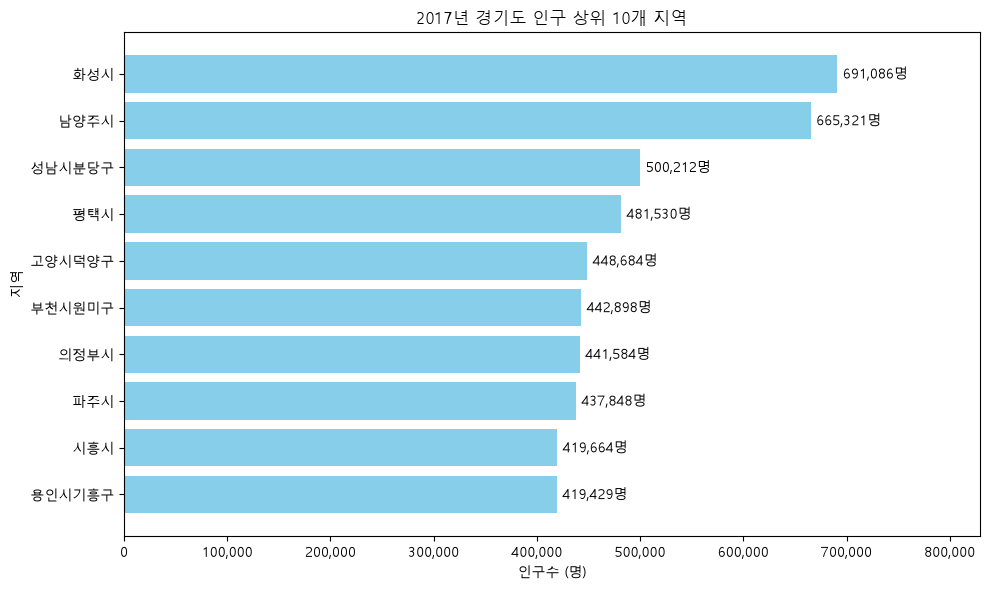

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 한글 글꼴 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2017년 인구 상위 10개 지역
population_top10 = df[2017].nlargest(10)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(population_top10.index, population_top10.values, color='skyblue')
ax.invert_yaxis()
ax.set_title('2017년 경기도 인구 상위 10개 지역')
ax.set_xlabel('인구수 (명)')
ax.set_ylabel('지역')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.bar_label(bars, labels=[f'{value:,}명' for value in population_top10], padding=4)
ax.set_xlim(0, population_top10.max() * 1.2)

plt.tight_layout()
plt.show()

In [19]:
import copy
import branca.colormap as cm
from IPython.display import display

# 2007년과 2017년의 인구 차이 (단위: 명)
population_change = df[2017] - df[2007]
max_change = population_change.abs().max()

# 0을 기준으로 파란색(감소) - 흰색 - 빨간색(증가)
color_scale = cm.LinearColormap(
    colors=['blue', 'white', 'red'],
    index=[-max_change, 0, max_change],
    vmin=-max_change,
    vmax=max_change,
    caption='2007~2017 인구 증감 (명)'
)

# 지도에 사용할 경계 정보에 연도별 값 추가
change_geo = copy.deepcopy(geo_data)
for feature in change_geo['features']:
    region = feature['properties']['name']
    feature['properties']['population_2007'] = f"{df.loc[region, 2007]:,}명"
    feature['properties']['population_2017'] = f"{df.loc[region, 2017]:,}명"
    feature['properties']['change_text'] = f"{population_change.loc[region]:+,}명"
    feature['properties']['change_value'] = int(population_change.loc[region])

change_map = folium.Map(location=[36.5502, 126.982], zoom_start=9)
folium.GeoJson(
    change_geo,
    style_function=lambda feature: {
        'fillColor': color_scale(feature['properties']['change_value']),
        'color': 'gray',
        'weight': 1,
        'fillOpacity': 0.7,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'population_2007', 'population_2017', 'change_text'],
        aliases=['지역', '2007년', '2017년', '증감'],
    )
).add_to(change_map)
color_scale.add_to(change_map)

display(change_map)


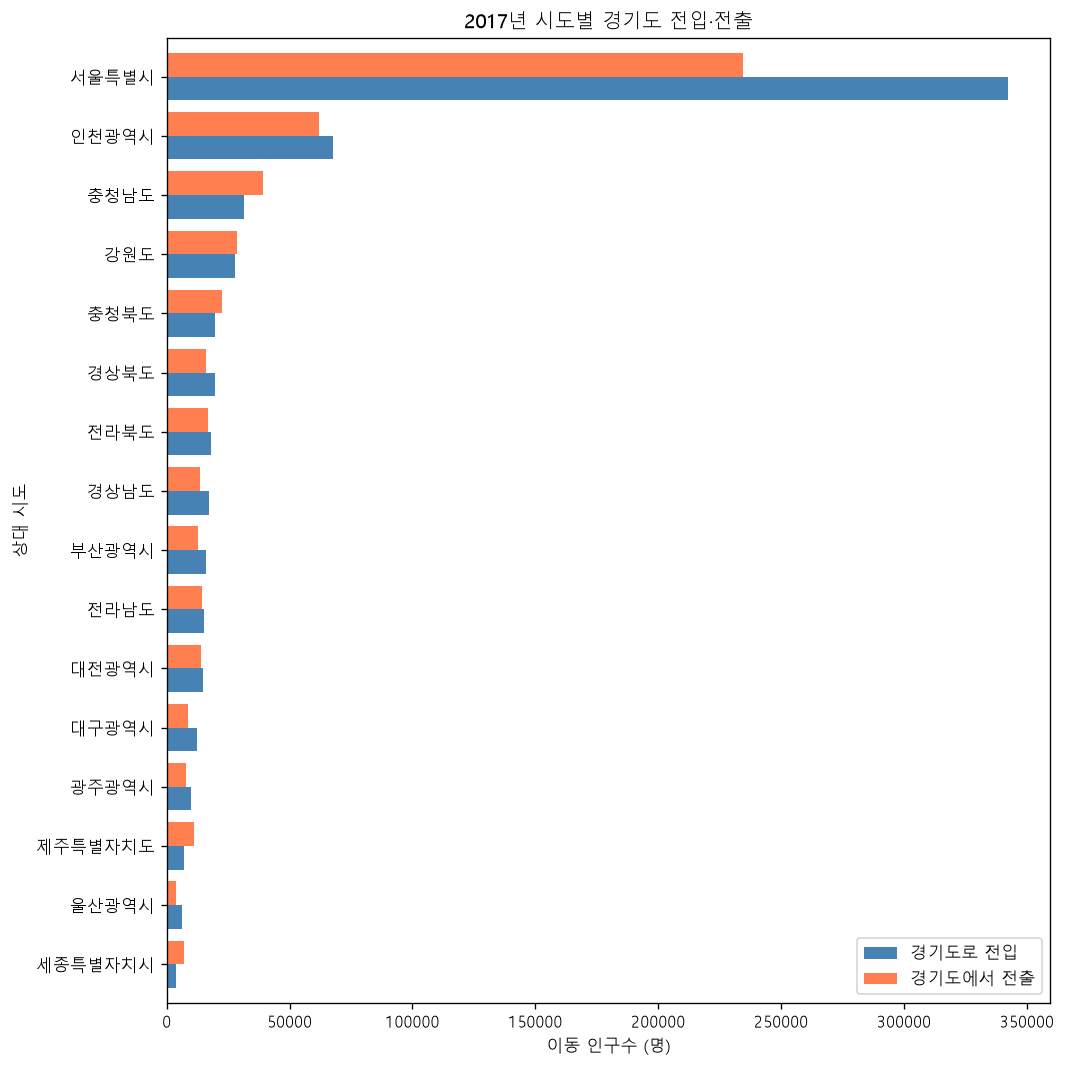

In [20]:
import base64
import io
from html import escape
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# 시도별 전출입 자료 불러오기
migration = pd.read_excel('../Data/시도별 전출입 인구수.xlsx')
migration = migration.iloc[1:].copy()  # 첫 번째 단위 설명 행 제거
migration['전출지별'] = migration['전출지별'].ffill()
migration['2017'] = pd.to_numeric(migration['2017'], errors='raise')

# 경기도 밖의 지역과 오간 이동만 선택
incoming = migration.loc[
    (migration['전입지별'] == '경기도') &
    (~migration['전출지별'].isin(['전국', '경기도'])),
    ['전출지별', '2017']
].set_index('전출지별')['2017']
outgoing = migration.loc[
    (migration['전출지별'] == '경기도') &
    (~migration['전입지별'].isin(['전국', '경기도'])),
    ['전입지별', '2017']
].set_index('전입지별')['2017']
flow = pd.concat([incoming.rename('경기도로 전입'), outgoing.rename('경기도에서 전출')], axis=1)
flow = flow.sort_values('경기도로 전입', ascending=True)

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
ax = flow.plot.barh(figsize=(9, 9), color=['steelblue', 'coral'], width=0.8)
ax.set_title('2017년 시도별 경기도 전입·전출')
ax.set_xlabel('이동 인구수 (명)')
ax.set_ylabel('상대 시도')
ax.legend()
ax.figure.tight_layout()

buffer = io.BytesIO()
ax.figure.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
plt.close(ax.figure)
chart_base64 = base64.b64encode(buffer.getvalue()).decode('ascii')
map_src = escape(change_map.get_root().render(), quote=True)

display(HTML(
    '<div style="display:flex; flex-wrap:wrap; gap:16px; align-items:flex-start">'
    '<div style="flex:1 1 440px; min-width:0">'
    '<h3>2007~2017년 경기도 인구 증감</h3>'
    f'<iframe srcdoc="{map_src}" title="경기도 인구 증감 지도" '
    'style="width:100%;height:700px;border:0"></iframe></div>'
    '<div style="flex:1 1 440px; min-width:0">'
    '<h3>2017년 경기도 전입·전출</h3>'
    f'<img src="data:image/png;base64,{chart_base64}" alt="시도별 경기도 전입 전출 막대그래프" '
    'style="width:100%;height:auto"></div></div>'
))